# 2 · Calibrazione del piano della lama di luce

Con la lama proiettata sul master a `z` noto, ogni pixel del baricentro della lama si porta nello spazio oggetto intersecando il suo raggio con il piano `z = costante` (modello di camera del notebook 1). I punti di tutte le viste giacciono sul piano della lama, che si stima ai minimi quadrati: `z = A·x + B·y + C`.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.laser import laser_centroids
from lightsheet3d.lightplane import fit_plane, plane_errors
from lightsheet3d.pipeline import calibrate_camera, calibrate_light_plane

## Estrazione della lama

Il nucleo della lama è saturo su tutti i canali, mentre la carta chiara ha il rosso alto ma verde e blu più bassi: si usa `min(B, G, R) ≥ 235`, si scartano le componenti piccole (riflessi) e si calcola il baricentro di ogni riga. Le righe senza lama non producono punti (nessuna interpolazione).

1390 righe con lama su 1420


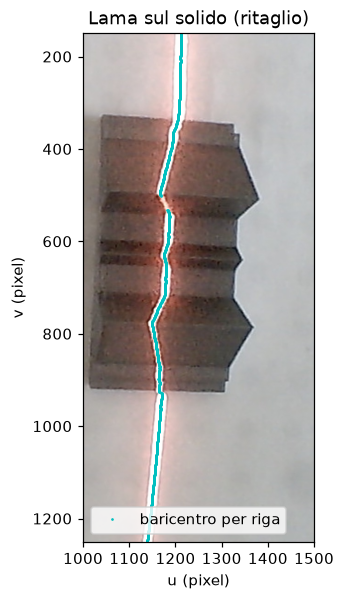

In [2]:
img = cv.imread(str(DATA / "scans" / "30o34.jpg"))
uv = laser_centroids(img)
print(f"{len(uv)} righe con lama su {img.shape[0]}")

x0, x1, y0, y1 = 1000, 1500, 150, 1250
fig, ax = plt.subplots(figsize=(5, 6))
ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
ax.plot(*uv.T, "c.", ms=1.5, label="baricentro per riga")
ax.set(xlim=(x0, x1), ylim=(y1, y0), xlabel="u (pixel)", ylabel="v (pixel)", title="Lama sul solido (ritaglio)")
ax.grid(False); ax.legend(loc="lower left")
fig.savefig(FIGURES / "laser_centroids.png", bbox_inches="tight")

## Piano e validazione

In [3]:
camera = calibrate_camera(DATA / "camera_calibration")
lp = calibrate_light_plane(DATA / "light_plane_calibration", camera.model)
A, B, C = lp.plane
cal, val = lp.points[~lp.is_validation], lp.points[lp.is_validation]
rms = lambda p: np.sqrt((plane_errors(lp.plane, p) ** 2).mean())
print(f"piano: z = {A:.3f}·x + {B:.4f}·y + {C:.1f}")
print(f"punti: {len(cal)} di calibrazione, {len(val)} di validazione (10%, scelti a caso)")
print(f"scarto ortogonale dal piano: calibrazione rms {rms(cal):.3f} mm | validazione rms {rms(val):.3f} mm | validazione max {np.abs(plane_errors(lp.plane, val)).max():.2f} mm")

print("\nvalidazione più severa: si esclude un'intera vista (z) e si ricalcola il piano sulle altre")
for z in np.unique(lp.points[:, 2]):
    m = lp.points[:, 2] == z
    e = plane_errors(fit_plane(lp.points[~m]), lp.points[m])
    print(f"  fuori z = {z:.0f} mm: rms {np.sqrt((e**2).mean()):.2f} mm")

piano: z = 3.670·x + 0.0103·y + 180.9
punti: 7668 di calibrazione, 852 di validazione (10%, scelti a caso)
scarto ortogonale dal piano: calibrazione rms 0.526 mm | validazione rms 0.511 mm | validazione max 1.44 mm

validazione più severa: si esclude un'intera vista (z) e si ricalcola il piano sulle altre
  fuori z = 300 mm: rms 0.97 mm
  fuori z = 310 mm: rms 0.12 mm
  fuori z = 320 mm: rms 0.28 mm
  fuori z = 330 mm: rms 1.17 mm
  fuori z = 340 mm: rms 0.91 mm
  fuori z = 350 mm: rms 0.12 mm


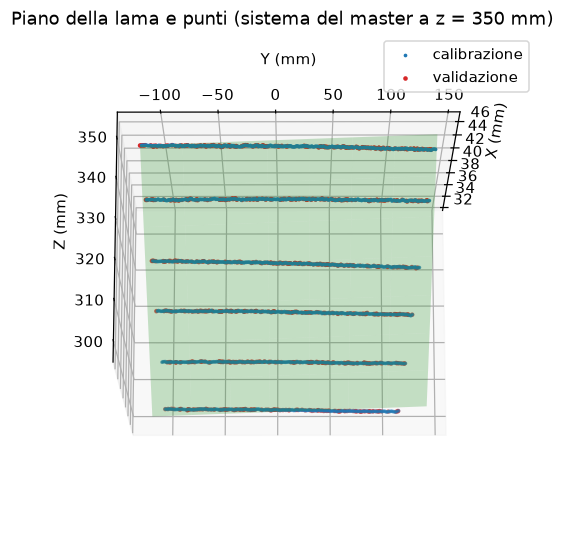

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
sub = slice(None, None, 6)
ax.scatter(*cal[sub].T, s=2, c="tab:blue", label="calibrazione")
ax.scatter(*val.T, s=4, c="tab:red", label="validazione")
gx, gy = np.meshgrid(np.linspace(*np.percentile(lp.points[:, 0], [0, 100]), 8), np.linspace(*np.percentile(lp.points[:, 1], [0, 100]), 8))
ax.plot_surface(gx, gy, A * gx + B * gy + C, alpha=0.25, color="tab:green")
ax.set(xlabel="X (mm)", ylabel="Y (mm)", zlabel="Z (mm)", title="Piano della lama e punti (sistema del master a z = 350 mm)")
ax.legend()
ax.view_init(elev=np.degrees(np.arcsin(-1 / np.sqrt(A**2 + B**2 + 1))), azim=np.degrees(np.arctan2(B, A)))  # di fronte al piano
fig.savefig(FIGURES / "light_plane.png", bbox_inches="tight")

**Lettura.** Lo scarto sui punti esclusi (~0.5 mm) coincide con quello di calibrazione. Escludendo un'intera vista l'errore varia da ~0.1 a ~1.1 mm: è l'ordine di grandezza dell'incertezza sulla quota. Usando anche le viste con `z > 350 mm` (oltre il master principale) l'errore sale (rms ~0.95 mm) e la base di appoggio risulta traslata di ~10 mm, per questo sono escluse.